# Linear regression with gradient descent

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

## Exercise 1: The dataset
1. Visualize the data `X` and `y`.
2. How many feature dimensions are contained? 

In [2]:
def make_dataset1(N=300, slope=65.7, intercept=-8.4, noise=49.0, seed=42):
    rng = np.random.default_rng(seed)
    x = rng.normal(0.0, 1.0, N)
    y = slope * x + intercept + rng.normal(0.0, noise, N)
    X = np.column_stack([np.ones(N), x])
    return X, y

X, y = make_dataset1()

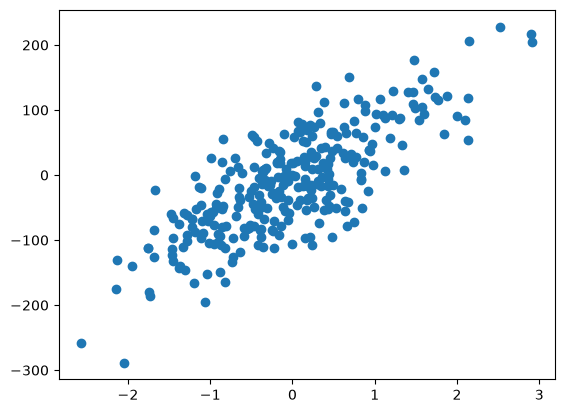

In [3]:
plt.scatter(X.T[1], y)

## Exercise 2: Analytical solution
OLS linear regression has an analytical solution. Let's quickly explore it using sklearn as a reference.
1. Use sklearn's `LinearRegression()` to fit a linear regression model. Set `fit_intercept=False` because we are using the augmented notation.
2. Print the learned weights from the model's attribute `coef_`.

In [4]:
rgs = LinearRegression(fit_intercept=False)
rgs.fit(X, y)
rgs.coef_

array([-8.879697  , 67.44403537])

## Exercise 3: Linear regression
OLS Linear regression, in augmented form, simply is $\mathbf{\hat{y}}=\mathbf{X}\mathbf{w}$. 
1. Write the function `linear_regression(X, w)` taking data `X` and weights `w`, and returning the outputs `y`.

In [5]:
def linear_regression(X, w): return X @ w

## Exercise 4: The mean squared error cost function

OLS linear regression uses the mean squared error (MSE) as cost function: $J(\mathbf{w}) = \sum^N(\mathbf{y} - \mathbf{X}\mathbf{w})^2$.

1. Write the function `mean_squared_error(X, y, w)` taking the data `X`, labels `y`, and weights `w`, and returning a scalar representing the cost $J(\mathbf{w})$.
2. Evaluate your implemented cost function $J(\mathbf{w})$ by varying the parameter $w_{0}\in[-500, 600]$ and you can set the bias term $w_{1}=0$, using the training data `X_train` and labels `y_train`. Plot the resulting cost function.


In [6]:
def mean_squared_error(X, y, w):
    return np.mean(np.square((X@w) - y))

## Exercise 5: The gradient
The derivative of the MSE is:
$$\frac{\delta L}{\delta w_j} = -\frac{1}{N}\sum_i^Nx_{ij}(y_i-\mathbf{x}_{i}\mathbf{w}) = \frac{1}{N}\sum_i^Nx_{ij}(\mathbf{x}_{i}\mathbf{w} - y_i)$$
1. Implement the function `gradient(X, y, w)` that computes this gradient.

In [7]:
def gradient(X, y, w):
    return (2 / len(y)) * X.T @ (X @ w - y)

## Exercise 6: Gradient descent
Gradient descent is an iterative scheme that updates the weights at every iteration as follows:
$$w_j^t = w_j^{t-1} - \alpha \frac{\delta L}{\delta w_j}$$
Here, $\alpha$ is the learning rate.
1. Implement the function `gradient_descent(X, y, alpha, n_iter)` that does the following:
   1. Normally, one would assign random values to the initial weight vector. Here, assign [0, -400]. 
   2. Loop over iterations: for each, compute the gradient and update the weights
1. The function should output the learned weights, as well as the cost at each iteration.


In [8]:
def gradient_descent(X, y, alpha, n_iter):
    W = [0, -400]

    costs = []
    for _ in range(n_iter):
        costs.append(mean_squared_error(X, y, W))
        W -= alpha * gradient(X, y, W)

    return costs, W

## Exercise 7: Learn a linear regression model
1. Use gradient descent to optimize the weights on the training data.
2. Visualize the cost across iterations.
3. Visualize the data and the learned linear regression.
4. Compare your obtained weights with those from sklearn.

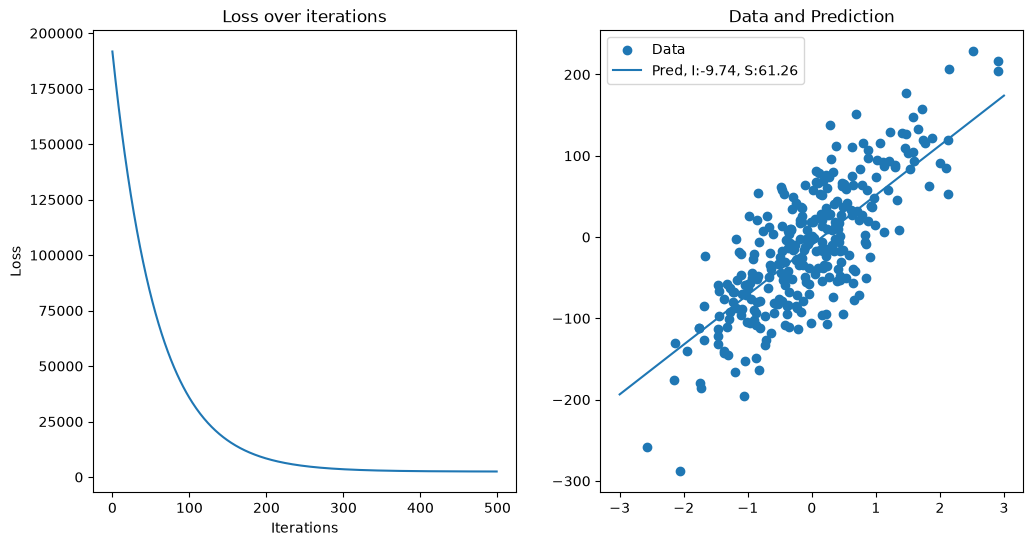

In [9]:
costs, W = gradient_descent(X, y, 0.005, 500)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].set(title="Loss over iterations", xlabel="Iterations", ylabel="Loss")
ax[0].plot(costs)


ax[1].set(title="Data and Prediction")
ax[1].scatter(X.T[1], y, label="Data")

n=300
x = np.column_stack([np.ones(n), np.linspace(-3, 3, num=n)])

ax[1].plot(x.T[1], W@x.T, label=f"Pred, I:{W[0]:.2f}, S:{W[1]:.2f}")
ax[1].legend()

## Exercise 8: Number of iterations and learning rate
1. Repeat the gradient descent with `n_iter=[2, 5, 10, 20, 40]` and `alpha=0.1`. Plot a scatter plot with each of the linear fits, and plot the MSE with for each a dot at the final cost. What do you observe?
1. Repeat the gradient descent with `alpha=[1e-4, 1e-2, 1e-1, 1]` and `n_iter=5`. Plot a scatter plot with each of the linear fits, and plot the MSE with for each a dot at the final cost. What do you observe?
1. Set `alpha=3` and `n_iter=10`. Plot the MSE, and a dot with the final cost value. What do you observe?

/tmp/nix-shell.604xVZ/ipykernel_53678/3693920587.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


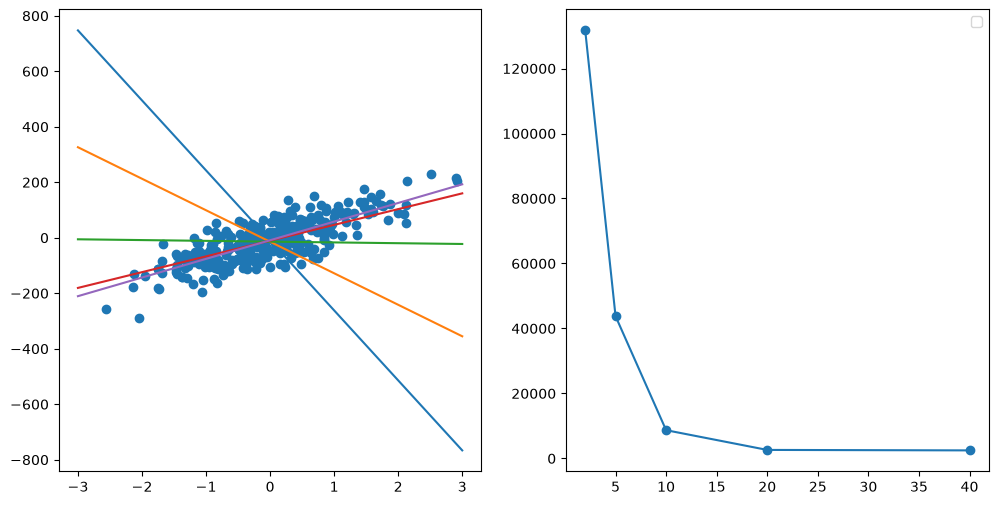

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].scatter(X.T[1], y)
final_costs = []
for n_iter in [2, 5, 10, 20, 40]:
    costs, W = gradient_descent(X, y, 0.1, n_iter)

    ax[0].plot(x.T[1], W@x.T, label=f"{n_iter} iters")
    final_costs.append((n_iter, costs[-1]))

ax[1].plot(*zip(*final_costs), marker="o")
plt.legend()
plt.show()

/tmp/nix-shell.604xVZ/ipykernel_53678/1712451266.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


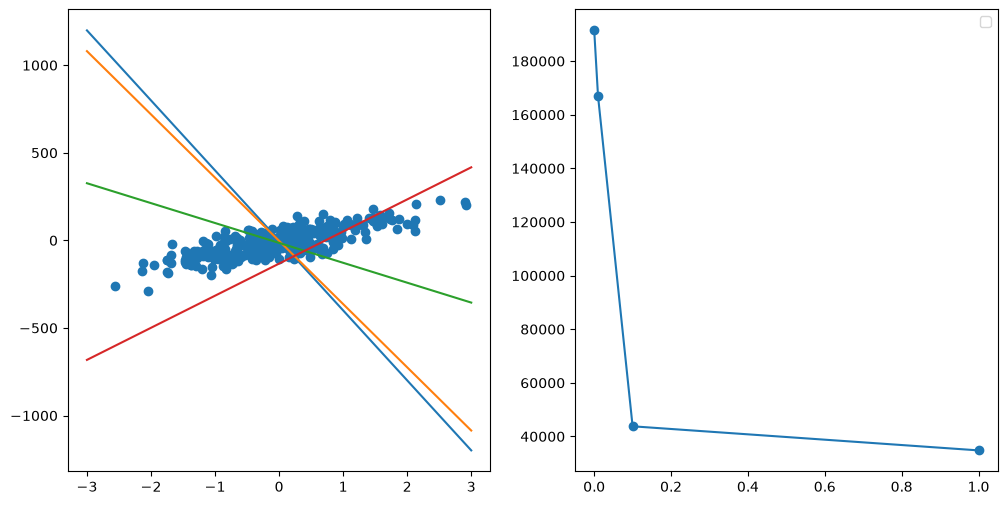

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].scatter(X.T[1], y)
final_costs = []
for alpha in [1e-4, 1e-2, 1e-1, 1]:
    costs, W = gradient_descent(X, y, alpha, 5)

    ax[0].plot(x.T[1], W@x.T, label=f"{n_iter} iters")
    final_costs.append((alpha, costs[-1]))

ax[1].plot(*zip(*final_costs), marker="o")
plt.legend()
plt.show()

'MSE: 2.6154897026967844e+18'

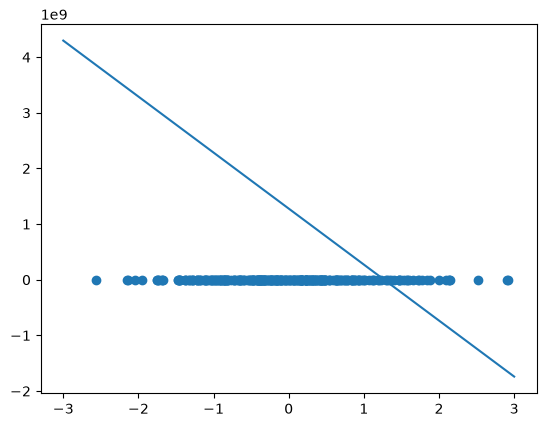

In [12]:
costs, W = gradient_descent(X, y, 3, 10)

plt.scatter(X.T[1], y)
plt.plot(x.T[1], W@x.T, label=f"{n_iter} iters")

f"MSE: {mean_squared_error(X, y, W)}"

## Exercise 9: Pitfalls of gradient descent

1. Visualize the dataset. 
2. Modify your linear_regression such that you can fit a model $f(\mathbf{x})=\sin(\mathbf{w}^T\mathbf{x})$.  
3. Set $w_{0}=1$ and evaluate the cost function $J(w_{0})$ for values $w_{0}\in[-4\pi,4\pi]$. Visualize your results.
4. What would happen if you applied the gradient descent approach?


In [13]:
def make_dataset2(N=400, noise=0.75, seed=42):
    rng = np.random.default_rng(seed)
    x = np.linspace(0.0, 4.0 * np.pi, N)
    y = np.sin(x) + rng.normal(0.0, noise, N)
    X = np.column_stack([np.ones(N), x])
    return X, y

X, y = make_dataset2()


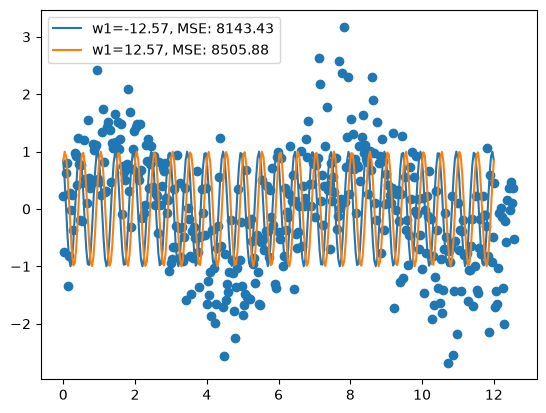

In [20]:
plt.scatter(X.T[1], y)

def linear_regression(X, w): return np.sin(X @ w)


n=300
x = np.column_stack([np.ones(n), np.linspace(0, 12, num=n)])

for w1 in [-4 * np.pi, 4 * np.pi]:
    w = np.array([1, w1])
    plt.plot(x.T[1], linear_regression(x, w), label=f"w1={w1:.2f}, MSE: {mean_squared_error(X, y, w):.2f}")

plt.legend()